Von MP4 zu Audio + Background
Original MP4
   ↓ Extract audio (keep original SR)
   ↓ Separate vocals/background (at original SR)
   ↓ Convert vocals & background stems → 48 kHz WAV
   ↓ Denoise vocals (48 kHz WAV) for Synthesis
   ↓ Transcripe text using the original Audio
Audio + Background   



In [2]:
import os
import shutil
import shlex
import subprocess
import demucs.separate
from df.enhance import enhance, init_df, load_audio, save_audio
import json
import requests
import time

def transcribe_with_whisperx(audio_file_path, language=None, enable_diarization=True, min_speakers=1, max_speakers=10, whisperx_url="http://whisperx:5001"):
    """Transcribe audio using WhisperX API service with diarization support."""
    print(f"Transcribing audio file with WhisperX: {audio_file_path}")
    
    # Check if WhisperX service is available
    try:
        health_response = requests.get(f"{whisperx_url}/health", timeout=10)
        if health_response.status_code != 200:
            raise Exception("WhisperX service not healthy")
        print("✅ WhisperX service is healthy")
    except Exception as e:
        print(f"❌ WhisperX service unavailable: {e}")
        return None
    
    # Prepare the request
    with open(audio_file_path, 'rb') as audio_file:
        files = {'audio': audio_file}
        data = {
            'language': language or 'en',
            'diarize': str(enable_diarization).lower(),
            'min_speakers': str(min_speakers),
            'max_speakers': str(max_speakers),
            'format': 'json'
        }
        
        print(f"📤 Sending audio to WhisperX API...")
        print(f"   Language: {data['language']}")
        print(f"   Diarization: {data['diarize']}")
        print(f"   Speaker range: {min_speakers}-{max_speakers}")
        
        try:
            response = requests.post(
                f"{whisperx_url}/transcribe",
                files=files,
                data=data,
                timeout=900  # 5 minutes timeout
            )
            
            if response.status_code == 200:
                result = response.json()
                print(f"✅ Transcription complete. Found {len(result.get('segments', []))} segments.")
                
                # Print preview with speaker information if available
                for i, segment in enumerate(result.get('segments', [])[:5]):  # First 5 segments
                    start = segment.get('start', 0)
                    end = segment.get('end', 0)
                    text = segment.get('text', '').strip()
                    speaker = segment.get('speaker', None)
                    
                    if speaker:
                        print(f"[{start:06.1f} --> {end:06.1f}] [{speaker}] {text}")
                    else:
                        print(f"[{start:06.1f} --> {end:06.1f}] {text}")
                
                if len(result.get('segments', [])) > 5:
                    print("...")
                
                return result
            else:
                print(f"❌ WhisperX API error: {response.status_code}")
                print(f"Response: {response.text}")
                return None
                
        except requests.exceptions.Timeout:
            print("❌ WhisperX API timeout - file might be too large")
            return None
        except Exception as e:
            print(f"❌ Error calling WhisperX API: {e}")
            return None

def separate_vocals(input_audio_path, output_dir, model='mdx_extra'):
    """
    Separate vocals and no-vocals with Demucs and save to custom output_dir.
    """
    print(f"Separating vocals from {input_audio_path}...")

    # Run Demucs CLI separation
    cmd = f'--two-stems vocals -n {model} "{input_audio_path}"'
    demucs.separate.main(shlex.split(cmd))

    base_name = os.path.splitext(os.path.basename(input_audio_path))[0]
    demucs_output_dir = os.path.join("separated", model, base_name)

    vocals_src = os.path.join(demucs_output_dir, "vocals.wav")
    no_vocals_src = os.path.join(demucs_output_dir, "no_vocals.wav")

    os.makedirs(output_dir, exist_ok=True)

    vocals_dst = os.path.join(output_dir, f"{base_name}_vocals.wav")
    no_vocals_dst = os.path.join(output_dir, f"{base_name}_no_vocals.wav")

    shutil.copy2(vocals_src, vocals_dst)
    shutil.copy2(no_vocals_src, no_vocals_dst)

    print(f"Vocals saved to: {vocals_dst}")
    print(f"No vocals saved to: {no_vocals_dst}")

    return vocals_dst, no_vocals_dst  # Return paths of saved files

def convert_to_48k_wav(input_audio_path, output_wav_path):
    """
    Convert any audio input to 48kHz stereo WAV using ffmpeg.
    """
    print(f"Converting {input_audio_path} to 48kHz WAV at {output_wav_path}...")
    subprocess.run([
        'ffmpeg', '-y', '-i', input_audio_path,
        '-ar', '48000',
        '-ac', '2',
        output_wav_path
    ], check=True)
    print("Conversion done.")

def denoise_audio(input_wav_path, output_wav_path):
    """
    Denoise/enhance the WAV audio using DeepFilterNet.
    """
    print(f"Denoising audio {input_wav_path} to {output_wav_path}...")
    model, df_state, _ = init_df()
    audio, _ = load_audio(input_wav_path, sr=df_state.sr())
    enhanced = enhance(model, df_state, audio)
    save_audio(output_wav_path, enhanced, df_state.sr())
    print("Denoising done.")

def separate_audio_from_video(video_path, audio_out_path, muted_video_out_path):
    """Extract audio from video and save both audio and muted video separately."""
    
    # Ensure output directories exist
    os.makedirs(os.path.dirname(audio_out_path), exist_ok=True)
    os.makedirs(os.path.dirname(muted_video_out_path), exist_ok=True)
    
    # Extract audio (48 kHz stereo WAV)
    audio_cmd = [
        "ffmpeg", "-y", "-i", video_path,
        "-vn", "-acodec", "pcm_s16le", "-ar", "48000", "-ac", "2",
        audio_out_path
    ]

    # Remove audio from video
    muted_video_cmd = [
        "ffmpeg", "-y", "-i", video_path,
        "-an", muted_video_out_path
    ]

    print("🔊 Extracting audio...")
    subprocess.run(audio_cmd, check=True)
    print(f"✅ Audio saved to: {audio_out_path}")

    print("🎥 Saving muted video...")
    subprocess.run(muted_video_cmd, check=True)
    print(f"✅ Muted video saved to: {muted_video_out_path}")

def write_transcription_to_json(result, output_path):
    """Write the WhisperX transcription result to a JSON file."""
    os.makedirs(os.path.dirname(output_path), exist_ok=True)  # Create output dir
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(result, f, indent=2, ensure_ascii=False)
    print(f"✅ JSON transcript saved to: {output_path}")

def write_transcription_to_srt(result, output_path):
    """Convert WhisperX result to SRT format and save."""
    os.makedirs(os.path.dirname(output_path), exist_ok=True)
    
    srt_content = ""
    for i, segment in enumerate(result.get('segments', []), 1):
        start_time = format_timestamp_srt(segment.get('start', 0))
        end_time = format_timestamp_srt(segment.get('end', 0))
        text = segment.get('text', '').strip()
        speaker = segment.get('speaker', '')
        
        if speaker:
            text = f"[{speaker}] {text}"
        
        srt_content += f"{i}\n{start_time} --> {end_time}\n{text}\n\n"
    
    with open(output_path, 'w', encoding='utf-8') as f:
        f.write(srt_content)
    
    print(f"✅ SRT transcript saved to: {output_path}")

def format_timestamp_srt(seconds):
    """Format timestamp for SRT format."""
    hours = int(seconds // 3600)
    minutes = int((seconds % 3600) // 60)
    seconds = seconds % 60
    return f"{hours:02d}:{minutes:02d}:{seconds:06.3f}".replace('.', ',')


/venv/lib/python3.10/site-packages/df/io.py:9: UserWarning: `torchaudio.backend.common.AudioMetaData` has been moved to `torchaudio.AudioMetaData`. Please update the import path.
  from torchaudio.backend.common import AudioMetaData


I use a function to make sure all audio, video, etc. are in one folder. To increase structure of the repo

In [3]:
def generate_pipeline_paths(video_path, base_output="../output"):
    video_title = os.path.splitext(os.path.basename(video_path))[0]
    root_dir = os.path.join(base_output, video_title)

    return {
        "root": root_dir,
        "audio_raw": os.path.join(root_dir, "audio", "original_unprocessed.wav"),
        "audio_vocals": os.path.join(root_dir, "audio", "vocals_raw.wav"),
        "audio_vocals_48k": os.path.join(root_dir, "audio", "vocals_48k.wav"),
        "audio_vocals_denoised": os.path.join(root_dir, "audio", "vocals_denoised.wav"),
        "video_muted": os.path.join(root_dir, "video", "video_muted.mp4"),
        "video_final": os.path.join(root_dir, "video", "video_final.mp4"),
        "transcript_json": os.path.join(root_dir, "transcripts", "transcript.json"),
        "demucs_out": os.path.join(root_dir, "demucs")
    }


this is the main function to use the entire pipeline 

Von MP4 zu Audio + Background + Transcriped text
   

In [4]:
def full_video_audio_pipeline(video_path, base_output="../output", enable_diarization=True, min_speakers=1, max_speakers=10, language=None):
    """
    Complete pipeline: video → audio separation → vocal isolation → denoising → WhisperX transcription with diarization
    Skips preprocessing steps if intermediate files already exist.
    """
    from df.enhance import enhance, init_df, load_audio, save_audio

    paths = generate_pipeline_paths(video_path, base_output)
    os.makedirs(paths["root"], exist_ok=True)

    # Step 1: Separate audio and muted video (skip if files exist)
    if not os.path.exists(paths["audio_raw"]) or not os.path.exists(paths["video_muted"]):
        print("🎵 Separating audio from video...")
        separate_audio_from_video(video_path, paths["audio_raw"], paths["video_muted"])
    else:
        print("✅ Raw audio and muted video already exist, skipping separation...")

    # Step 2: Separate vocals with Demucs (skip if vocals exist)
    if not os.path.exists(paths["audio_vocals"]):
        print("🎤 Separating vocals with Demucs...")
        vocals_path, _ = separate_vocals(paths["audio_raw"], output_dir=os.path.dirname(paths["audio_vocals"]))
        shutil.move(vocals_path, paths["audio_vocals"])  # Rename into our structure
    else:
        print("✅ Vocals already separated, skipping Demucs...")

    # Step 3: Convert vocals to 48kHz WAV (skip if converted file exists)
    if not os.path.exists(paths["audio_vocals_48k"]):
        print("🔄 Converting vocals to 48kHz WAV...")
        convert_to_48k_wav(paths["audio_vocals"], paths["audio_vocals_48k"])
    else:
        print("✅ 48kHz vocals already exist, skipping conversion...")

    # Step 4: Denoise vocals (skip if denoised file exists)
    if not os.path.exists(paths["audio_vocals_denoised"]):
        print("🔧 Denoising vocals...")
        model_df, df_state, _ = init_df()
        audio, _ = load_audio(paths["audio_vocals_48k"], sr=df_state.sr())
        enhanced = enhance(model_df, df_state, audio)
        save_audio(paths["audio_vocals_denoised"], enhanced, df_state.sr())
    else:
        print("✅ Denoised vocals already exist, skipping denoising...")

    # Step 5: Transcribe with WhisperX API (always run unless transcript exists)
    # Generate transcript paths if not in the paths dict
    transcript_json_path = paths.get("transcript_json", os.path.join(paths["root"], "transcript.json"))
    transcript_srt_path = paths.get("transcript_srt", os.path.join(paths["root"], "transcript.srt"))
    
    if not os.path.exists(transcript_json_path) or not os.path.exists(transcript_srt_path):
        print("🎤 Starting transcription with WhisperX...")
        result = transcribe_with_whisperx(
            paths["audio_vocals"], 
            language=language,
            enable_diarization=enable_diarization,
            min_speakers=min_speakers,
            max_speakers=max_speakers
        )
        
        if result:
            write_transcription_to_json(result, transcript_json_path)
            write_transcription_to_srt(result, transcript_srt_path)
        else:
            print("❌ Transcription failed!")
    else:
        print("✅ Transcription files already exist, skipping WhisperX...")

    print(f"🎉 Pipeline complete. All outputs saved under: {paths['root']}")
    return paths


Here is how to use this pipeline:

In [5]:
# Updated usage example with diarization options
video_path = "../input/green_nature.mp4"
pipeline_paths = full_video_audio_pipeline(
    video_path, 
    enable_diarization=True,  # Enable speaker separation
    min_speakers=1,           # Minimum number of speakers
    max_speakers=2,           # Maximum number of speakers  
    language="en"             # Language (optional, auto-detect if None)
)


🎵 Separating audio from video...
🔊 Extracting audio...


ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

✅ Audio saved to: ../output/green_nature/audio/original_unprocessed.wav
🎥 Saving muted video...


frame= 2167 fps=675 q=-1.0 Lsize=    7116kB time=00:01:12.13 bitrate= 808.2kbits/s speed=22.5x    
video:7092kB audio:0kB subtitle:0kB other streams:0kB global headers:0kB muxing overhead: 0.343229%
[libx264 @ 0x63da050c8380] frame I:16    Avg QP:19.04  size: 20551
[libx264 @ 0x63da050c8380] frame P:950   Avg QP:23.41  size:  5564
[libx264 @ 0x63da050c8380] frame B:1201  Avg QP:27.78  size:  1371
[libx264 @ 0x63da050c8380] consecutive B-frames: 20.0% 16.2%  6.6% 57.2%
[libx264 @ 0x63da050c8380] mb I  I16..4: 29.6% 32.5% 37.9%
[libx264 @ 0x63da050c8380] mb P  I16..4:  3.3%  4.4%  1.4%  P16..4: 33.1% 12.7%  5.4%  0.0%  0.0%    skip:39.7%
[libx264 @ 0x63da050c8380] mb B  I16..4:  0.3%  0.3%  0.1%  B16..8: 40.7%  6.2%  1.6%  direct: 1.4%  skip:49.4%  L0:58.4% L1:35.6% BI: 6.0%
[libx264 @ 0x63da050c8380] 8x8 transform intra:45.2% inter:40.4%
[libx264 @ 0x63da050c8380] coded y,uvDC,uvAC intra: 50.0% 70.2% 29.2% inter: 11.2% 13.7% 1.4%
[libx264 @ 0x63da050c8380] i16 v,h,dc,p: 24% 38% 11% 26%


✅ Muted video saved to: ../output/green_nature/video/video_muted.mp4
🎤 Separating vocals with Demucs...
Separating vocals from ../output/green_nature/audio/original_unprocessed.wav...


...

Vocals saved to: ../output/green_nature/audio/original_unprocessed_vocals.wav
No vocals saved to: ../output/green_nature/audio/original_unprocessed_no_vocals.wav
🔄 Converting vocals to 48kHz WAV...
Converting ../output/green_nature/audio/vocals_raw.wav to 48kHz WAV at ../output/green_nature/audio/vocals_48k.wav...
Conversion done.
🔧 Denoising vocals...


ffmpeg version 4.4.2-0ubuntu0.22.04.1 Copyright (c) 2000-2021 the FFmpeg developers
  built with gcc 11 (Ubuntu 11.2.0-19ubuntu1)
  configuration: --prefix=/usr --extra-version=0ubuntu0.22.04.1 --toolchain=hardened --libdir=/usr/lib/x86_64-linux-gnu --incdir=/usr/include/x86_64-linux-gnu --arch=amd64 --enable-gpl --disable-stripping --enable-gnutls --enable-ladspa --enable-libaom --enable-libass --enable-libbluray --enable-libbs2b --enable-libcaca --enable-libcdio --enable-libcodec2 --enable-libdav1d --enable-libflite --enable-libfontconfig --enable-libfreetype --enable-libfribidi --enable-libgme --enable-libgsm --enable-libjack --enable-libmp3lame --enable-libmysofa --enable-libopenjpeg --enable-libopenmpt --enable-libopus --enable-libpulse --enable-librabbitmq --enable-librubberband --enable-libshine --enable-libsnappy --enable-libsoxr --enable-libspeex --enable-libsrt --enable-libssh --enable-libtheora --enable-libtwolame --enable-libvidstab --enable-libvorbis --enable-libvpx --enab

2025-06-26 21:39:49 | INFO     | DF | Running on torch 2.3.0+cu121
2025-06-26 21:39:49 | INFO     | DF | Running on host f586ccc6ea9a
2025-06-26 21:39:49 | INFO     | DF | Loading model settings of DeepFilterNet3
2025-06-26 21:39:49 | INFO     | DF | Using DeepFilterNet3 model at /root/.cache/DeepFilterNet/DeepFilterNet3
2025-06-26 21:39:49 | INFO     | DF | Initializing model `deepfilternet3`
2025-06-26 21:39:49 | INFO     | DF | Found checkpoint /root/.cache/DeepFilterNet/DeepFilterNet3/checkpoints/model_120.ckpt.best with epoch 120
2025-06-26 21:39:49 | INFO     | DF | Running on device cuda:0
2025-06-26 21:39:49 | INFO     | DF | Model loaded


fatal: not a git repository (or any of the parent directories): .git
/venv/lib/python3.10/site-packages/torch/nn/modules/conv.py:456: UserWarning: Plan failed with a cudnnException: CUDNN_BACKEND_EXECUTION_PLAN_DESCRIPTOR: cudnnFinalize Descriptor Failed cudnn_status: CUDNN_STATUS_NOT_SUPPORTED (Triggered internally at ../aten/src/ATen/native/cudnn/Conv_v8.cpp:919.)
  return F.conv2d(input, weight, bias, self.stride,


🎤 Starting transcription with WhisperX...
Transcribing audio file with WhisperX: ../output/green_nature/audio/vocals_raw.wav
✅ WhisperX service is healthy
📤 Sending audio to WhisperX API...
   Language: en
   Diarization: true
   Speaker range: 1-2
✅ Transcription complete. Found 0 segments.
✅ JSON transcript saved to: ../output/green_nature/transcripts/transcript.json
✅ SRT transcript saved to: ../output/green_nature/transcript.srt
🎉 Pipeline complete. All outputs saved under: ../output/green_nature


In [9]:
import difflib
import os
import re

def compare_transcriptions_whisperx(paths, original_text=None, max_chars=500,min_speakers=1, max_speakers=10):
    """
    Compare transcriptions from raw, vocals, and denoised audio using WhisperX API.
    Optionally, compare to a provided original text string.
    
    Args:
        paths: Dictionary from generate_pipeline_paths() with all file paths
        original_text: (str) The reference/original transcript to compare against
        max_chars: Number of characters to preview in each transcript
    """
    print("🔍 Comparing transcriptions from different audio versions (WhisperX API)...")

    # Transcribe all versions with WhisperX API
    result_raw = transcribe_with_whisperx(paths["audio_raw"], min_speakers=min_speakers, max_speakers=max_speakers)
    result_vocals = transcribe_with_whisperx(paths["audio_vocals"], min_speakers=min_speakers, max_speakers=max_speakers)
    result_denoised = transcribe_with_whisperx(paths["audio_vocals_denoised"], min_speakers=min_speakers, max_speakers=max_speakers)

    # Extract text
    def extract_text(result):
        if result and "result" in result and "segments" in result["result"]:
            return " ".join(seg.get("text", "").strip() for seg in result["result"]["segments"])
        return ""


    text_raw = extract_text(result_raw)
    text_vocals = extract_text(result_vocals)
    text_denoised = extract_text(result_denoised)

    # Print the text
    print("\n--- RAW AUDIO (WhisperX) ---\n", text_raw)
    print("\n--- VOCALS ONLY (WhisperX) ---\n", text_vocals)
    print("\n--- DENOISED VOCALS (WhisperX) ---\n", text_denoised)

    def normalize_text(text):
        # Entfernt Zeichensetzung und wandelt alles in Kleinbuchstaben um
        return re.sub(r'[^\w\s]', '', text).lower().strip()
    
    # Normalisierte Versionen
    norm_raw = normalize_text(text_raw)
    norm_vocals = normalize_text(text_vocals)
    norm_denoised = normalize_text(text_denoised)
    norm_original = normalize_text(original_text) if original_text else ""

    # Ähnlichkeitsvergleiche (ohne Zeichensetzung)
    sim_raw_vs_vocals = difflib.SequenceMatcher(None, norm_raw, norm_vocals).ratio()
    sim_raw_vs_denoised = difflib.SequenceMatcher(None, norm_raw, norm_denoised).ratio()
    sim_vocals_vs_denoised = difflib.SequenceMatcher(None, norm_vocals, norm_denoised).ratio()


    print("\n🔗 Similarity Scores (WhisperX):")
    print(f"Raw vs Vocals:     {sim_raw_vs_vocals:.2%}")
    print(f"Raw vs Denoised:   {sim_raw_vs_denoised:.2%}")
    print(f"Vocals vs Denoised:{sim_vocals_vs_denoised:.2%}")

    # If original text is provided, compare to it
    if original_text:
        original_text = original_text.strip()
        sim_raw_vs_orig = difflib.SequenceMatcher(None, text_raw, original_text).ratio()
        sim_vocals_vs_orig = difflib.SequenceMatcher(None, text_vocals, original_text).ratio()
        sim_denoised_vs_orig = difflib.SequenceMatcher(None, text_denoised, original_text).ratio()
        print("\n🔗 Similarity to ORIGINAL:")
        print(f"Raw vs Original:      {sim_raw_vs_orig:.2%}")
        print(f"Vocals vs Original:   {sim_vocals_vs_orig:.2%}")
        print(f"Denoised vs Original: {sim_denoised_vs_orig:.2%}")

    # Save all transcripts
    out_dir = os.path.join(paths["root"], "transcripts")
    os.makedirs(out_dir, exist_ok=True)
    if result_raw:
        write_transcription_to_json(result_raw, os.path.join(out_dir, "raw_whisperx.json"))
    if result_vocals:
        write_transcription_to_json(result_vocals, os.path.join(out_dir, "vocals_whisperx.json"))
    if result_denoised:
        write_transcription_to_json(result_denoised, os.path.join(out_dir, "denoised_whisperx.json"))

    print("\n📝 All WhisperX transcripts saved for manual review.")


original_text = """
And here, when conditions are just right it's possible to witness a rare and remarkable spectacle. The river is so crystal clear that its bed is bathed in sunlight. A magical landscape of miniature mountains and valleys. As the sun climbs in the sky, bubbles of gas appear. Evidence of photosynthesis. They absorb carbon dioxide and use the sun's power to synthesise the sugars that the plant needs to grow. Now, in late afternoon, bubbles of oxygen make the river water fizz like champagne. The plants can become so buoyant with gas that they rise to the surface, even carrying the bedrock with them. Only in this remote water world can this spectacular natural wonder be seen.  
"""

video_path = "../input/green_nature.mp4"
paths = generate_pipeline_paths(video_path)
compare_transcriptions_whisperx(paths, original_text=original_text, min_speakers=1, max_speakers=2)

🔍 Comparing transcriptions from different audio versions (WhisperX API)...
Transcribing audio file with WhisperX: ../output/green_nature/audio/original_unprocessed.wav
✅ WhisperX service is healthy
📤 Sending audio to WhisperX API...
   Language: en
   Diarization: true
   Speaker range: 1-2
✅ Transcription complete. Found 0 segments.
Transcribing audio file with WhisperX: ../output/green_nature/audio/vocals_raw.wav
✅ WhisperX service is healthy
📤 Sending audio to WhisperX API...
   Language: en
   Diarization: true
   Speaker range: 1-2
✅ Transcription complete. Found 0 segments.
Transcribing audio file with WhisperX: ../output/green_nature/audio/vocals_denoised.wav
✅ WhisperX service is healthy
📤 Sending audio to WhisperX API...
   Language: en
   Diarization: true
   Speaker range: 1-2
✅ Transcription complete. Found 0 segments.

--- RAW AUDIO (WhisperX) ---
 And here, when conditions are just right, it's possible to witness a rare and remarkable spectacle. The river is so crystal cl

In [10]:
import librosa
import librosa.display
import matplotlib.pyplot as plt

def plot_waveform(audio_path, title="Waveform"):
    y, sr = librosa.load(audio_path, sr=None)
    plt.figure(figsize=(14, 3))
    librosa.display.waveshow(y, sr=sr)
    plt.title(title)
    plt.xlabel("Time (s)")
    plt.ylabel("Amplitude")
    plt.grid(True)
    plt.tight_layout()
    plt.show()


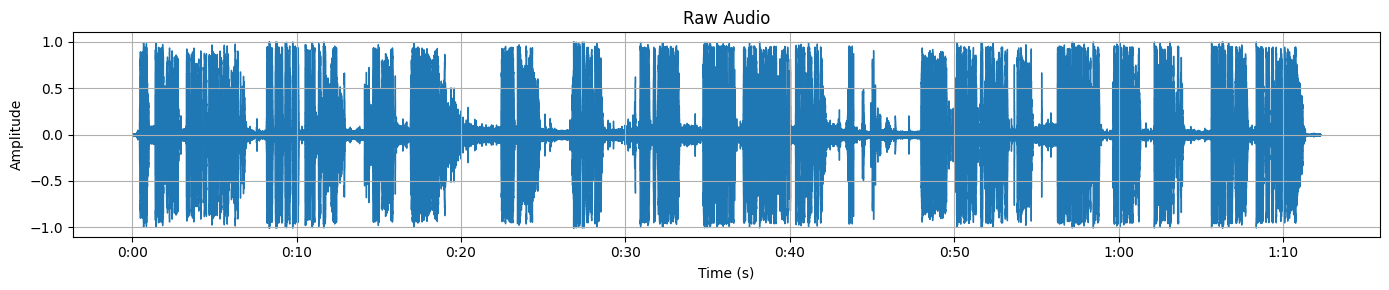

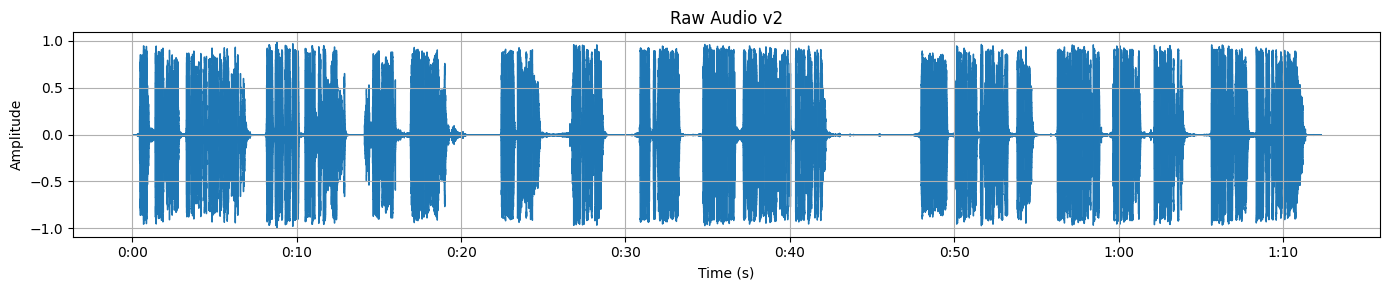

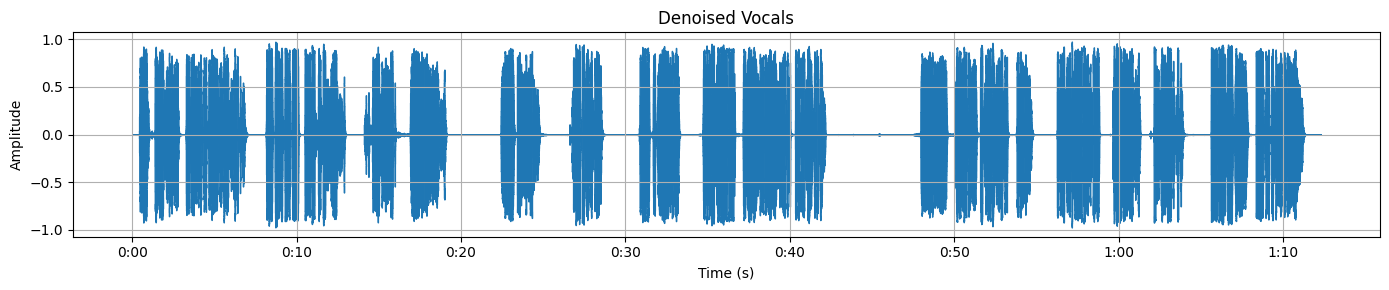

In [12]:
plot_waveform("../output/green_nature/audio/original_unprocessed.wav", title="Raw Audio")
plot_waveform("../output/green_nature/audio/vocals_raw.wav", title="Raw Audio v2")
plot_waveform("../output/green_nature/audio/vocals_denoised.wav", title="Denoised Vocals")


In [13]:
import numpy as np
def plot_spectrogram(audio_path, title="Spectrogram"):
    y, sr = librosa.load(audio_path, sr=None)
    D = librosa.amplitude_to_db(np.abs(librosa.stft(y)), ref=np.max)

    plt.figure(figsize=(14, 4))
    librosa.display.specshow(D, sr=sr, x_axis='time', y_axis='log')
    plt.title(title)
    plt.colorbar(format='%+2.0f dB')
    plt.tight_layout()
    plt.show()


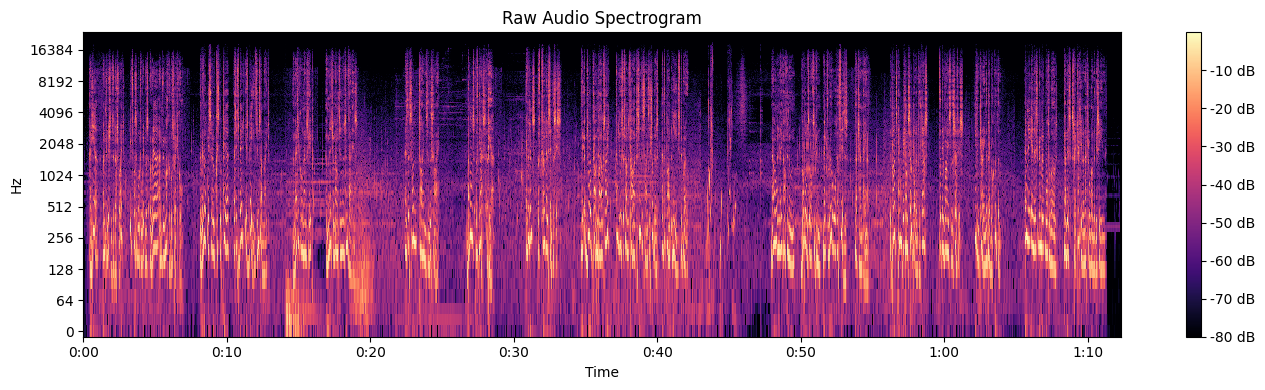

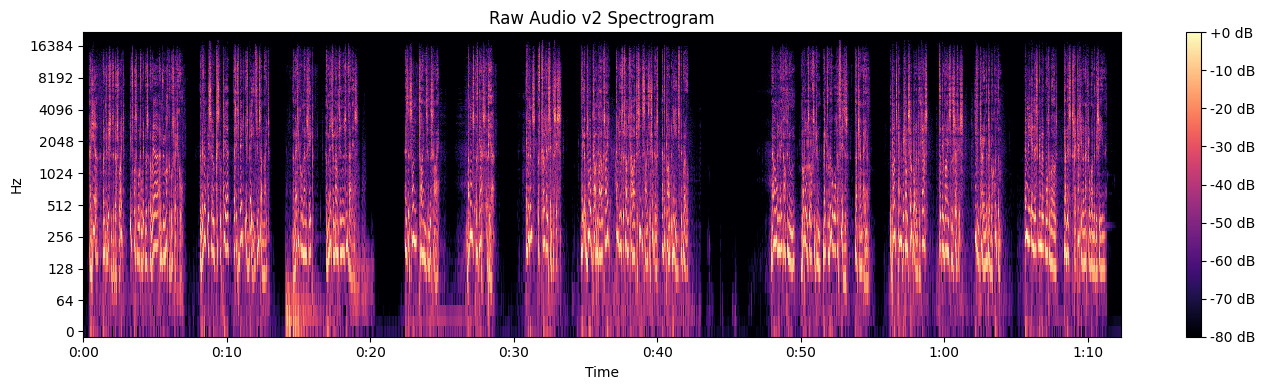

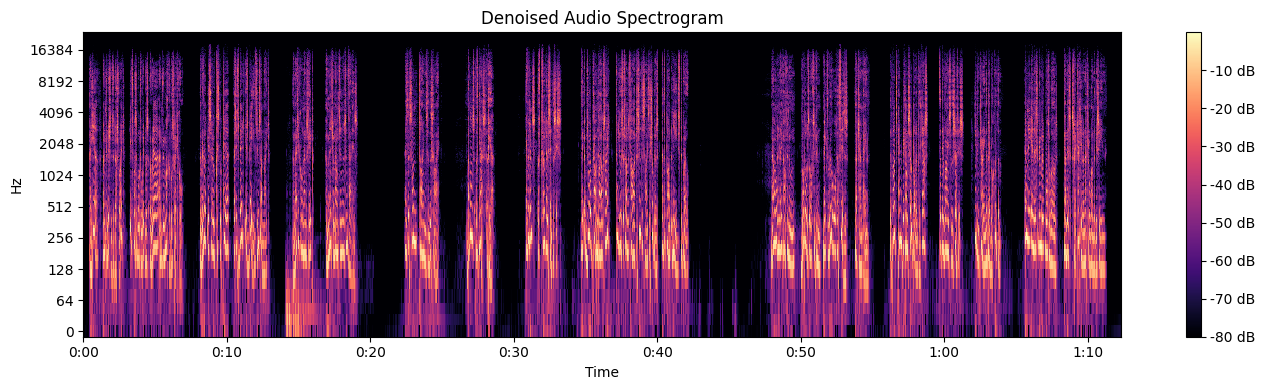

In [15]:
plot_spectrogram("../output/green_nature/audio/original_unprocessed.wav", title="Raw Audio Spectrogram")
plot_spectrogram("../output/green_nature/audio/vocals_raw.wav", title="Raw Audio v2 Spectrogram")
plot_spectrogram("../output/green_nature/audio/vocals_denoised.wav", title="Denoised Audio Spectrogram")
